# 05 · The final test: 24 Oct 2023 to 23 Oct 2026, run once

**What's frozen** (nothing below changes after this run):

- **Universe:** the 10 stocks from notebook 01.
- **Rules:** version 1 from notebook 03, `Params()` with its defaults: 20-day VWAP, 60-day σ, entry at z ≤ −2, exit back at VWAP or after 10 days.
- **Costs:** notebook 04's model, both scenarios.

**Pass/fail, decided before running.** Version 1 counts as having an edge only if, out-of-sample:

1. the EV per trade is **positive after costs** in the auction-fills scenario (the cheaper one), **and**
2. that EV is at least **2 standard errors above zero**, measured with trades grouped by month (Part B explains this).

This notebook's code was tested on the in-sample years first. This run is the first time it touches 2023–2026.

In [1]:
import sys
from math import sqrt
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from costs import add_spread, net_returns
from vwap_dip import END, SPLIT, START, Params, run

RESULTS = ROOT / "data" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
SYMBOLS = pd.read_csv(ROOT / "data" / "universe" / "universe_v1.csv")["yahoo_symbol"].tolist()

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#888780"

print(Params())

bars, all_trades = run(SYMBOLS)
bars = {s: add_spread(b) for s, b in bars.items()}
all_trades["net_auction"] = net_returns(all_trades, bars, cross_spread=False)
all_trades["net_spread"] = net_returns(all_trades, bars, cross_spread=True)

periods = {
    "in-sample 2016-2023": all_trades[(all_trades["entry_date"] >= START) & (all_trades["entry_date"] < SPLIT)],
    "out-of-sample 2023-2026": all_trades[all_trades["entry_date"] >= SPLIT],
}
periods["in-sample 2016-2023"].to_csv(RESULTS / "trades_in_sample.csv", index=False)
periods["out-of-sample 2023-2026"].to_csv(RESULTS / "trades_out_of_sample.csv", index=False)
{k: len(v) for k, v in periods.items()}

Params(vwap_days=20, sigma_days=60, entry_z=-2.0, max_days=10)


{'in-sample 2016-2023': 225, 'out-of-sample 2023-2026': 95}

## Part A · Trade results, side by side

In [2]:
def summarise(t):
    r = t["return"]
    return {
        "trades": len(t),
        "win rate %": 100 * (r > 0).mean(),
        "average win %": 100 * r[r > 0].mean(),
        "average loss %": 100 * r[r <= 0].mean(),
        "EV before costs %": 100 * r.mean(),
        "EV, auction fills %": 100 * t["net_auction"].mean(),
        "EV, cross the spread %": 100 * t["net_spread"].mean(),
        "median trade (before costs) %": 100 * r.median(),
        "share exiting back at VWAP %": 100 * (t["exit_reason"] == "back to VWAP").mean(),
        "average days held": t["days_held"].mean(),
    }


pd.DataFrame({k: summarise(v) for k, v in periods.items()}).round(2)

,in-sample 2016-2023,out-of-sample 2023-2026
trades,225.00,95.00
win rate %,52.00,68.42
average win %,7.43,5.98
average loss %,-8.64,-3.65
EV before costs %,-0.29,2.94
"EV, auction fills %",-0.39,2.83
"EV, cross the spread %",-1.73,1.77
median trade (before costs) %,0.27,2.49
share exiting back at VWAP %,38.67,42.11
average days held,8.67,8.44


## Part B · Could it be luck?

In notebook 03, the random-twin test *measured* how much an average of trades wobbles by chance. There's also a formula for it, and we already have every piece.

**The standard error.** In notebook 02 we used the fact that variances of independent days *add up*, which is why annual volatility is daily σ × √252. The same fact applies to trades:

- If each trade's return has standard deviation σ, the **sum** of n independent trades has variance n·σ².
- The **average** is the sum divided by n, so its variance is n·σ² / n² = σ²/n.
- Its standard deviation is therefore **σ / √n**. That's the *standard error* (SE) of the average.

Averages of many trades come out close to normally distributed, even though single trades don't. So the ±2σ rule from the start of the project applies to the average: if the true edge were zero, the measured average would land within ±2 SE of zero about 95% of the time. The ratio **t = EV / SE** says how many standard errors the result is from zero.

**One correction.** The formula assumes trades are independent, but notebook 02 showed they cluster on sell-off days. Trades in the same month can rise and fall together, so we also compute the SE treating each **month** as one block: the deviations from the average are added up within each month before squaring. This SE is larger and more honest. It's the one the pass/fail rule uses.

In [3]:
def significance(r, months):
    n, ev = len(r), r.mean()
    se_independent = r.std() / sqrt(n)
    se_by_month = sqrt(((r - ev).groupby(months).sum() ** 2).sum()) / n
    return {"EV %": 100 * ev, "SE % (independent)": 100 * se_independent, "t (independent)": ev / se_independent,
            "SE % (by month)": 100 * se_by_month, "t (by month)": ev / se_by_month}


rows = {}
for name, t in periods.items():
    months = t["entry_date"].dt.to_period("M")
    for col, label in [("return", "before costs"), ("net_auction", "auction fills"), ("net_spread", "cross the spread")]:
        rows[(name, label)] = significance(t[col], months)
sig = pd.DataFrame(rows).T
sig.round(2)

EV %  SE % (independent)  \
in-sample 2016-2023     before costs     -0.29                0.76   
                        auction fills    -0.39                0.76   
                        cross the spread -1.73                0.75   
out-of-sample 2023-2026 before costs      2.94                0.70   
                        auction fills     2.83                0.70   
                        cross the spread  1.77                0.68   

                                          t (independent)  SE % (by month)  \
in-sample 2016-2023     before costs                -0.38             1.12   
                        auction fills               -0.51             1.12   
                        cross the spread            -2.30             1.11   
out-of-sample 2023-2026 before costs                 4.18             0.72   
                        auction fills                4.04             0.72   
                        cross the spread             2.61             0.68   

                                          t (by month)  
in-sample 2016-2023     before costs             -0.26  
                        auction fills            -0.35  
                        cross the spread         -1.56  
out-of-sample 2023-2026 before costs              4.08  
                        auction fills             3.94  
                        cross the spread          2.60

The random-twin check from notebook 03, now on the out-of-sample years: the same stocks and holding lengths, entered on random out-of-sample days, 2,000 times.

In [4]:
rng = np.random.default_rng(42)
oos = periods["out-of-sample 2023-2026"]
opens = {s: b["open"].to_numpy() for s, b in bars.items()}
# random entry days inside the test period, leaving room for the longest hold before the data ends
pool = {s: np.flatnonzero(b.index >= SPLIT)[:-11] for s, b in bars.items()}


def random_twins_average():
    return np.mean([opens[s][e + h] / opens[s][e] - 1
                    for s, h in zip(oos["symbol"], oos["days_held"])
                    for e in [rng.choice(pool[s])]])


random_averages = np.array([random_twins_average() for _ in range(2000)])
print("strategy average before costs: %.2f%%" % (100 * oos["return"].mean()))
print("random runs, middle 90%%:       %.2f%% to %.2f%%" % (100 * np.percentile(random_averages, 5), 100 * np.percentile(random_averages, 95)))
print("random runs at least as good:  %.0f%%" % (100 * (random_averages >= oos["return"].mean()).mean()))

strategy average before costs: 2.94%
random runs, middle 90%:       -0.85% to 1.62%
random runs at least as good:  0%


## Part C · How many trades would it take to see a real edge?

Turn the standard error around. To show an edge of size *e* at t = 2 we need 2·σ/√n ≤ e, so **n ≥ (2σ / e)²**. With σ around 11% per trade:

In [5]:
sd = all_trades.loc[all_trades["entry_date"] >= START, "return"].std()
trades_per_year = len(all_trades[all_trades["entry_date"] >= START]) / 10
need = pd.DataFrame({f"edge {e:.2%}": {"trades needed": (2 * sd / e) ** 2,
                                        "years at our pace": (2 * sd / e) ** 2 / trades_per_year}
                     for e in [0.0025, 0.005, 0.01, 0.02]}).T
print("σ per trade: %.1f%% | trades per year: %.0f" % (100 * sd, trades_per_year))
need.round(0)

σ per trade: 10.4% | trades per year: 32


,trades needed,years at our pace
edge 0.25%,6888.0,215.0
edge 0.50%,1722.0,54.0
edge 1.00%,430.0,13.0
edge 2.00%,108.0,3.0


This is one of the most useful results of the project. A realistic edge for a simple strategy like this is a fraction of a percent per trade, and with these stocks' volatility it would take **many decades** of trading to tell it apart from luck. Ten stocks and daily bars can't settle the question either way. More stocks, or more frequent signals, would be needed.

## Part D · As a portfolio

So far we've looked at trades. An investor experiences a **portfolio**: €100,000 in 10 slots of €10,000. Each slot holds its stock during a trade, and otherwise keeps its cash on deposit at the **ECB deposit facility rate** (−0.5% in 2019–22, 4% in 2023–24, 2–2.5% since). The benchmark is **buy-and-hold**: €10,000 in each stock at the start of the period, never touched.

- **Sharpe ratio:** return *above cash* per unit of risk, (annual return − cash rate) ÷ annual volatility. From daily data it's the average daily excess return ÷ its standard deviation × √252: the average scales with 252 days and the standard deviation with √252. Borrowing at the cash rate to double a position doubles both the excess return and the volatility, so leverage doesn't change the Sharpe ratio. That's why it's the standard way to compare a strategy that's in the market 11% of the time with buy-and-hold, which always is.
- **Maximum drawdown:** the worst fall from a previous peak.

*Updated after the first run: idle cash now earns interest, and Sharpe ratios are measured above the cash rate. The first version ignored cash, which flattered buy-and-hold in 2023–26 (Sharpe 0.50 instead of 0.38), when cash paid 2–4%. The trades and the pass/fail test are unchanged.*

In [6]:
import io


def load_cash_rate():
    """ECB deposit facility rate as an annual fraction, downloaded once and cached in data/raw/."""
    path = ROOT / "data" / "raw" / "ecb_deposit_rate.csv"
    if not path.exists():
        from curl_cffi import requests  # comes with yfinance; handles the ECB's certificate on Windows
        url = "https://data-api.ecb.europa.eu/service/data/FM/D.U2.EUR.4F.KR.DFR.LEV?format=csvdata&startPeriod=2016-01-01"
        d = pd.read_csv(io.StringIO(requests.get(url, timeout=30).text))
        d[["TIME_PERIOD", "OBS_VALUE"]].to_csv(path, index=False)
    return pd.read_csv(path, index_col="TIME_PERIOD", parse_dates=True)["OBS_VALUE"].sort_index() / 100


days = pd.DatetimeIndex(sorted(set().union(*[b.loc[START:END].index for b in bars.values()])))
cash = load_cash_rate().reindex(days, method="ffill") / 252  # interest earned per trading day


def slot_daily(b, t, net_col):
    """One stock's slot: open-to-open returns while in a trade (costs taken on the first day) and a held flag."""
    o = b["open"]
    r = (o.shift(-1) / o - 1).fillna(0.0)
    ret = pd.Series(0.0, index=b.index)
    held = pd.Series(False, index=b.index)
    for entry, exit_, gross, net in zip(t["entry_date"], t["exit_date"], t["return"], t[net_col]):
        h = (b.index >= entry) & (b.index < exit_)
        ret[h] = r[h]
        held[h] = True
        ret.loc[entry] = (1 + ret.loc[entry]) * (1 + net) / (1 + gross) - 1
    return ret, held


def strategy_daily(net_col):
    parts = {s: slot_daily(b, all_trades[all_trades["symbol"] == s], net_col) for s, b in bars.items()}
    ret = pd.DataFrame({s: p[0] for s, p in parts.items()}).reindex(days).fillna(0.0)
    held = pd.DataFrame({s: p[1] for s, p in parts.items()}).reindex(days, fill_value=False).astype(bool)
    total = (ret + (~held).mul(cash, axis=0)).mean(axis=1)  # idle slots earn the cash rate
    return total, held.to_numpy().mean()


def buy_and_hold(start, end):
    o = pd.DataFrame({s: b["open"] for s, b in bars.items()}).reindex(days).ffill().loc[start:end]
    return (o / o.iloc[0]).mean(axis=1).pct_change().fillna(0.0)


strategy = {}
strategy["strategy, auction fills"], time_in_market = strategy_daily("net_auction")
strategy["strategy, cross the spread"], _ = strategy_daily("net_spread")


def period_returns(a, z):
    """Daily total returns of each portfolio over [a, z], with buy-and-hold starting fresh at a."""
    out = {name: d.loc[a:z] for name, d in strategy.items()}
    out["buy and hold"] = buy_and_hold(a, z)
    return {name: d.iloc[1:-1] for name, d in out.items()}  # first and last days have no full open-to-open move


def metrics(d):
    equity = (1 + d).cumprod()
    years = len(d) / 252
    excess = d - cash.reindex(d.index)
    return {"total return %": 100 * (equity.iloc[-1] - 1), "annual return %": 100 * (equity.iloc[-1] ** (1 / years) - 1),
            "annual volatility %": 100 * d.std() * sqrt(252), "Sharpe (above cash)": excess.mean() / excess.std() * sqrt(252),
            "max drawdown %": 100 * (equity / equity.cummax() - 1).min()}


PERIODS = {"in-sample": (START, SPLIT), "out-of-sample": (SPLIT, END), "full decade": (START, END)}
table = {(label, name): metrics(d) for label, (a, z) in PERIODS.items() for name, d in period_returns(a, z).items()}
print("share of slot-days spent in a trade: %.0f%%" % (100 * time_in_market))
pd.DataFrame(table).T.round(2)

share of slot-days spent in a trade: 11%


total return %  annual return %  \
in-sample     strategy, auction fills              -8.22            -1.20   
              strategy, cross the spread          -32.11            -5.31   
              buy and hold                         30.90             3.86   
out-of-sample strategy, auction fills              43.01            12.52   
              strategy, cross the spread           29.74             8.97   
              buy and hold                         29.00             8.76   
full decade   strategy, auction fills              30.94             2.69   
              strategy, cross the spread          -12.12            -1.27   
              buy and hold                         59.02             4.68   

                                          annual volatility %  \
in-sample     strategy, auction fills                   10.27   
              strategy, cross the spread                10.34   
              buy and hold                              28.38   
out-of-sample strategy, auction fills                    6.79   
              strategy, cross the spread                 6.68   
              buy and hold                              20.24   
full decade   strategy, auction fills                    9.37   
              strategy, cross the spread                 9.40   
              buy and hold                              25.96   

                                          Sharpe (above cash)  max drawdown %  
in-sample     strategy, auction fills                   -0.07          -36.83  
              strategy, cross the spread                -0.48          -42.09  
              buy and hold                               0.27          -54.61  
out-of-sample strategy, auction fills                    1.36           -3.97  
              strategy, cross the spread                 0.90           -4.23  
              buy and hold                               0.38          -21.02  
full decade   strategy, auction fills                    0.24          -36.83  
              strategy, cross the spread                -0.18          -42.09  
              buy and hold                               0.27          -54.61

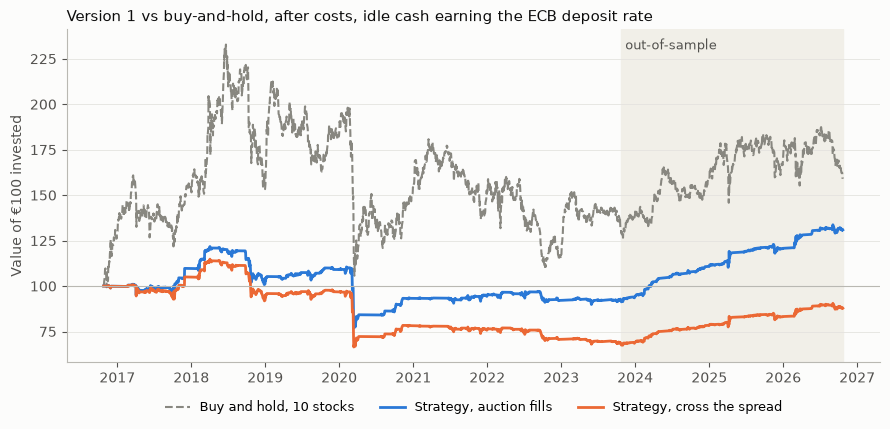

In [7]:
decade = period_returns(START, END)
fig, ax = plt.subplots(figsize=(9, 4.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.axvspan(pd.Timestamp(SPLIT), pd.Timestamp(END), color="#f1efe8", zorder=0)
ax.text(mdates.date2num(pd.Timestamp(SPLIT) + pd.Timedelta(days=20)), 0.94, "out-of-sample", transform=ax.get_xaxis_transform(), fontsize=9, color=MUTED)
ax.plot((1 + decade["buy and hold"]).cumprod() * 100, color=GREY, linewidth=1.5, linestyle="--", label="Buy and hold, 10 stocks")
ax.plot((1 + decade["strategy, auction fills"]).cumprod() * 100, color=BLUE, linewidth=2, label="Strategy, auction fills")
ax.plot((1 + decade["strategy, cross the spread"]).cumprod() * 100, color=ORANGE, linewidth=2, label="Strategy, cross the spread")
ax.axhline(100, color="#b9b8b2", linewidth=0.8)
ax.set_ylabel("Value of €100 invested", color=MUTED)
ax.set_title("Version 1 vs buy-and-hold, after costs, idle cash earning the ECB deposit rate", loc="left", fontsize=11, color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#b9b8b2")
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

## Part D2 · How much can we trust a Sharpe ratio?

A Sharpe ratio is an *estimate*, just like the EV per trade, so it has a standard error too. We can work it out from what we already have:

- Sharpe = (average annual excess return) ÷ (annual volatility). Most of its uncertainty comes from the **average** on top.
- By the √n logic from Part B, with *years* as the unit this time, the average annual return over T years has standard error ≈ annual volatility ÷ √T.
- Dividing by the annual volatility gives **SE(Sharpe) ≈ 1 / √T**, where T is the number of years.

The number of trades and the number of days don't appear: **only calendar time does.** Three years give ±0.58 per standard error, ten years ±0.32. A more careful formula adds terms for returns that aren't independent ([Lo, 2002, *The Statistics of Sharpe Ratios*](https://doi.org/10.2469/faj.v58.n4.2453)), but 1/√T is the core of it.

As a second check, we **reshuffle whole calendar months** with replacement 2,000 times and recompute the Sharpe ratio each time. Keeping each month intact preserves the way trades cluster within a month.

In [8]:
rng_boot = np.random.default_rng(7)


def sharpe(x):
    x = np.asarray(x)
    return x.mean() / x.std(ddof=1) * sqrt(252)


def month_bootstrap(x, n=2000):
    """2.5th and 97.5th percentiles of the Sharpe ratio when whole months are resampled with replacement."""
    months = [g.to_numpy() for _, g in x.groupby(x.index.to_period("M"))]
    k = len(months)
    draws = [sharpe(np.concatenate([months[i] for i in rng_boot.integers(0, k, k)])) for _ in range(n)]
    return np.percentile(draws, [2.5, 97.5])


rows = {}
for label, (a, z) in PERIODS.items():
    for name, d in period_returns(a, z).items():
        x = d - cash.reindex(d.index)
        years = len(x) / 252
        sr, se = sharpe(x), 1 / sqrt(years)
        lo, hi = month_bootstrap(x)
        rows[(label, name)] = {"Sharpe": sr, "years": years, "SE ≈ 1/√years": se,
                               "-2 SE": sr - 2 * se, "+2 SE": sr + 2 * se,
                               "bootstrap 2.5%": lo, "bootstrap 97.5%": hi}
sharpe_table = pd.DataFrame(rows).T
sharpe_table.round(2)

Sharpe  years  SE ≈ 1/√years  -2 SE  \
in-sample     strategy, auction fills      -0.07   7.10           0.38  -0.82   
              strategy, cross the spread   -0.48   7.10           0.38  -1.23   
              buy and hold                  0.27   7.10           0.38  -0.48   
out-of-sample strategy, auction fills       1.36   3.03           0.57   0.21   
              strategy, cross the spread    0.90   3.03           0.57  -0.25   
              buy and hold                  0.38   3.03           0.57  -0.77   
full decade   strategy, auction fills       0.24  10.14           0.31  -0.39   
              strategy, cross the spread   -0.18  10.14           0.31  -0.81   
              buy and hold                  0.27  10.14           0.31  -0.36   

                                          +2 SE  bootstrap 2.5%  \
in-sample     strategy, auction fills      0.68           -0.81   
              strategy, cross the spread   0.27           -1.17   
              buy and hold                 1.03           -0.53   
out-of-sample strategy, auction fills      2.50            0.81   
              strategy, cross the spread   2.05            0.31   
              buy and hold                 1.53           -0.46   
full decade   strategy, auction fills      0.87           -0.42   
              strategy, cross the spread   0.45           -0.83   
              buy and hold                 0.90           -0.39   

                                          bootstrap 97.5%  
in-sample     strategy, auction fills                0.97  
              strategy, cross the spread             0.43  
              buy and hold                           1.12  
out-of-sample strategy, auction fills                2.20  
              strategy, cross the spread             1.62  
              buy and hold                           1.33  
full decade   strategy, auction fills                1.05  
              strategy, cross the spread             0.61  
              buy and hold                           0.97

**Sharpe ratio by calendar year** (2016 left out: it's only nine weeks; 2026 runs to 23 October).

In [9]:
decade_excess = {name: d - cash.reindex(d.index) for name, d in period_returns(START, END).items()}
yearly = pd.DataFrame({name: x.loc["2017":].groupby(x.loc["2017":].index.year).apply(sharpe)
                       for name, x in decade_excess.items()}).T
yearly.columns = [str(y) if y < 2026 else "2026 (to Oct)" for y in yearly.columns]
yearly.round(2)

,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026 (to Oct)
"strategy, auction fills",0.87,-0.56,1.34,-0.74,0.34,-0.35,-0.33,2.99,0.76,1.15
"strategy, cross the spread",0.51,-0.96,0.88,-1.02,-0.44,-1.02,-1.38,2.17,0.48,0.70
buy and hold,0.84,0.17,0.88,-0.23,0.00,-0.75,0.86,0.79,0.31,-0.34


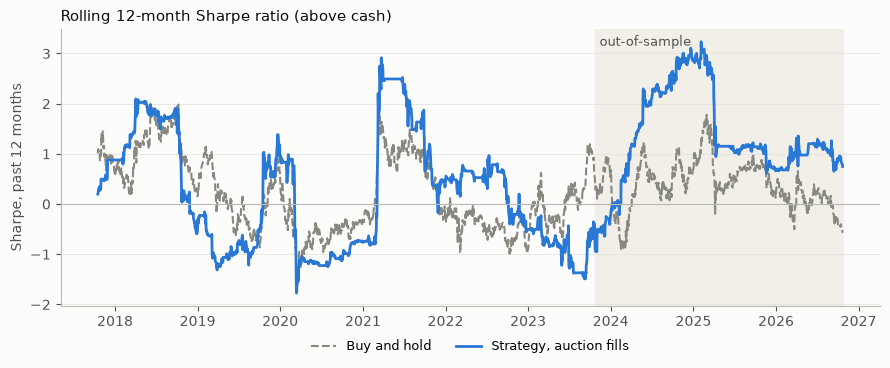

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.axvspan(pd.Timestamp(SPLIT), pd.Timestamp(END), color="#f1efe8", zorder=0)
ax.text(mdates.date2num(pd.Timestamp(SPLIT) + pd.Timedelta(days=20)), 0.94, "out-of-sample", transform=ax.get_xaxis_transform(), fontsize=9, color=MUTED)
for name, color, style in [("buy and hold", GREY, "--"), ("strategy, auction fills", BLUE, "-")]:
    x = decade_excess[name]
    rolling = x.rolling(252).mean() / x.rolling(252).std() * sqrt(252)
    ax.plot(rolling, color=color, linewidth=2 if style == "-" else 1.5, linestyle=style, label=name.capitalize())
ax.axhline(0, color="#b9b8b2", linewidth=0.8)
ax.set_ylabel("Sharpe, past 12 months", color=MUTED)
ax.set_title("Rolling 12-month Sharpe ratio (above cash)", loc="left", fontsize=11, color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#b9b8b2")
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

**Reading the Sharpe ratios**

- **2023–26:** the strategy scores 1.36 after auction-fill costs, against 0.38 for buy-and-hold. The ±2 SE range from the 1/√T rule is 0.21 to 2.50, and the month-reshuffle range is 0.81 to 2.20: above zero either way. When crossing the spread it's 0.90, and the ±2 SE range (−0.25 to 2.05) includes zero.
- **The reshuffled range is narrower, and that's a warning, not reassurance.** Reshuffling months from 2023–26 can only rebuild 2023–26-style markets. It can never produce a 2020 or a 2022. The 1/√T rule makes no such assumption.
- **Full decade:** 0.24 for the strategy (−0.18 crossing the spread) against 0.27 for buy-and-hold. Over ten years, per unit of risk, the strategy did no better than just holding the 10 stocks, and every range comfortably includes zero.
- **Year by year,** the strategy's Sharpe was negative in 4 of the 9 full years (2018, 2020, 2022, 2023). 2024 (2.99) is by far its best year. The rolling chart shows the same swings.
- **What it does offer is a smoother ride:** volatility of about 9% a year against 26%, and a worst fall of 37% against 55% over the decade, because it's in the market only 11% of the time. But the Sharpe ratio already allows for that, and per unit of risk it isn't better over the decade.

## Part E · Checks added after seeing the result

The out-of-sample result is the opposite of the in-sample one. A surprise like that has to be checked for bugs and fragility before anyone believes it. **These checks were added after the run.** They change nothing about the rules or the pass/fail rule; they only help read the result.

**Check 1 · Could it be a data error?** If Yahoo had missed a reverse split (several shares merged into one), the price would jump up many times over in one day, and any trade holding through it would show a fake gain. Here are the biggest one-day rises during the test period:

In [11]:
rises = {}
for s in SYMBOLS:
    h = pd.read_csv(ROOT / "data" / "processed" / f"{s}.csv", index_col="Date", parse_dates=True).loc[SPLIT:END]
    day = h["Adj Close"].pct_change()
    rises[s] = {"biggest one-day rise %": round(100 * day.max(), 1), "date": day.idxmax().date()}
pd.DataFrame(rises).T

,biggest one-day rise %,date
OHLA.MC,16.9,2024-12-27
EDR.MC,20.6,2026-02-26
AMP.MC,14.6,2024-04-11
ORY.MC,23.8,2025-02-21
TUB.MC,10.3,2026-04-08
ENC.MC,8.9,2026-07-22
NXT.MC,17.5,2024-02-16
DOM.MC,10.6,2025-07-21
GSJ.MC,9.5,2024-03-01
ADX.MC,8.7,2025-11-20


None comes close to the 5× to 100× jump a missed consolidation would cause. The biggest is +24% (Oryzon). The eDreams date, 26 Feb 2026, lines up with documented news: the day it reported results ([Forbes](https://forbes.es/economia/880598/edreams-vuela-casi-un-20-en-bolsa-tras-multiplicar-por-diez-su-beneficio-neto-en-sus-primeros-nueve-meses/)).

**Check 2 · Is it a few lucky trades?**

In [12]:
best5 = oos.nlargest(5, "return")
print("EV before costs, all %d trades:         %.2f%%" % (len(oos), 100 * oos["return"].mean()))
print("EV before costs, without the 5 best:    %.2f%%" % (100 * oos["return"].drop(best5.index).mean()))
g = oos.groupby("symbol")["return"]
pd.DataFrame({"trades": g.size(), "EV %": 100 * g.mean(), "win rate %": 100 * g.apply(lambda x: (x > 0).mean())}).round(1).T

EV before costs, all 95 trades:         2.94%
EV before costs, without the 5 best:    1.98%


symbol,ADX.MC,AMP.MC,DOM.MC,EDR.MC,ENC.MC,GSJ.MC,NXT.MC,OHLA.MC,ORY.MC,TUB.MC
trades,9.0,9.0,13.0,11.0,10.0,6.0,5.0,9.0,13.0,10.0
EV %,1.5,5.4,1.0,5.4,1.6,2.9,6.9,0.7,4.7,0.9
win rate %,66.7,100.0,53.8,72.7,70.0,50.0,60.0,44.4,84.6,70.0


No. It's still about +2% without the five best trades, and positive in all 10 stocks.

**Check 3 · Does it depend on the kind of market?** Average trade by the year it was entered, over the whole decade:

In [13]:
decade = all_trades[all_trades["entry_date"] >= START].copy()
by_year = decade.groupby(decade["entry_date"].dt.year)["return"].agg(trades="size", ev="mean")
by_year["ev"] *= 100
by_year["period"] = np.where(by_year.index >= 2024, "out-of-sample", "in-sample")
by_year.loc[2023, "period"] = "both"
by_year.rename(columns={"ev": "EV before costs %"}).round(2).T

entry_date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
trades,1,35,40,25,37,29,30,35,31,29,28
EV before costs %,-0.56,2.58,-0.85,1.63,-3.56,0.91,-1.08,0.07,3.99,2.1,2.45
period,in-sample,in-sample,in-sample,in-sample,in-sample,in-sample,in-sample,both,out-of-sample,out-of-sample,out-of-sample


In [14]:
# every 3-year window inside the in-sample years: did any of them look as good as 2023-2026?
windows = {f"{a}-{a + 2}": 100 * decade.loc[decade["entry_date"].dt.year.between(a, a + 2), "return"].mean() for a in range(2017, 2022)}
windows["out-of-sample (Oct 2023 - Oct 2026)"] = 100 * oos["return"].mean()
pd.Series(windows, name="EV before costs %").round(2)

2017-2019                              0.97
2018-2020                             -1.23
2019-2021                             -0.71
2020-2022                             -1.44
2021-2023                             -0.04
out-of-sample (Oct 2023 - Oct 2026)    2.94
Name: EV before costs %, dtype: float64

Yes, strongly. The strategy made money in calm years, or years where sell-offs reversed quickly (2017, 2019, 2024–2026). It lost in years with drawn-out sell-offs (2018, 2020, 2022). No 3-year stretch in the in-sample years came close to the test period.

**Check 4 · The whole decade together**, grouping trades by month and, more roughly, by year:

In [15]:
def pooled(r, groups):
    ev = r.mean()
    se = sqrt(((r - ev).groupby(groups).sum() ** 2).sum()) / len(r)
    return {"trades": len(r), "EV %": 100 * ev, "SE %": 100 * se, "t": ev / se}


pd.DataFrame({
    "grouped by month": pooled(decade["return"], decade["entry_date"].dt.to_period("M")),
    "grouped by year": pooled(decade["return"], decade["entry_date"].dt.year),
}).T.round(2)

,trades,EV %,SE %,t
grouped by month,320.0,0.67,0.86,0.78
grouped by year,320.0,0.67,0.71,0.95


## Verdict

**By the rule written before the run, version 1 passes.** Out-of-sample, the EV after auction-fill costs is **+2.83% per trade, t = 3.9** (trades grouped by month). Even crossing the spread it's +1.77% (t = 2.6), and none of the 2,000 random-entry runs did as well. As a portfolio, its **Sharpe ratio above cash is 1.36**, against 0.38 for buy-and-hold.

**The checks say to read that carefully:**

1. **It isn't a data error or a few lucky trades.** No missed share consolidations, still about +2% without the five best trades, and positive in all 10 stocks.
2. **It depends on the kind of market.** The strategy makes money when sell-offs reverse quickly and loses when they drag on. 2023–2026 had no drawn-out sell-off: the April 2025 crash reversed within days, which is exactly the market dip-buying needs.
3. **The test window was unusually good.** No 3-year stretch in-sample came close.
4. **Over the full decade the evidence is weak:** about +0.7% per trade before costs, t below 1, and a Sharpe ratio of 0.24 against buy-and-hold's 0.27. Its Sharpe was negative in 4 of the 9 full years.
5. **Our pass/fail rule had a blind spot.** Grouping by month handles trades that cluster in the same sell-off. It doesn't handle whole *years* going well or badly together. Three test years are really just three draws of what kind of market it was.

**Conclusion for the write-up:** buying 2σ dips below a 20-day rolling VWAP in liquid Spanish small caps was profitable in Oct 2023 to Oct 2026 after realistic costs. But a decade of data shows the result depends on whether sell-offs reverse quickly, and this data can't show an edge that holds across market conditions. Telling those apart would take more independent market periods: more years, or many more stocks and markets.